# Multigroup cross section generation and FW-CADIS

In this notebook, we create multi-group cross sections (mgxs) from an openmc simulation.
Then, we use the deterministic code to generate FW-CADIS based weight windows, after which we compare the figure of merit 
on the same geometry, showing $O(10^2)$ improvement!

In [1]:
import jax
import jax.numpy as jnp
import numpy as onp
import matplotlib.pyplot as plt
jax.config.update("jax_platforms", "cpu")
jax.config.update("jax_enable_x64", True)
import jax_sn
from jax_sn.operator_creation import DefaultMultiGroupStrategy

We will use the small [mcbb](https://github.com/timobogaarts/mcbb) library which handles the construction of a 1D blanket simulation and handles the I/O of 
OpenMC data.

- `OpenMCSettingsBlanket` is a small wrapper around the OpenMC settings object with reasonable defaults for blanket simulations.
- `OpenMCSymmetricLinearBlanketSimulation` constructs a symmetric linear blanket (i.e. | shield | breeding zone | plasma | breeding zone | shield) geometry and 
tags the appropriate materials from the `mcbb.examples.hcpb()` material library.
- `create_mgxs_library` creates a multi-group cross section library from the OpenMC simulation results, which can then be converted to a dictionary of data arrays for use in `jax-sn`. This is done using the `mgxs_lib_to_data_dicts` function.
- The resulting `openmc_data` dictionary contains simply a key for each material with two arrays: the total and scattering cross section (which includes the multiplication factor -- `nu-scatter`).


Inspect the functions in the `mcbb` library to see how.

In [2]:
import mcbb 
hcpb_blanket = mcbb.examples.hcpb()
n_samples_per_batch = 1e5
groups_list         = [14.1e6, 1e6, 300, 10, 0]
n_x_tally           = 200
settings            = mcbb.blanket_base.OpenMCSettingsBlanket(True, "openmc_data/", 10, n_samples_per_batch , seed = 29072026)
simulation_symm     = mcbb.linear_blanket.OpenMCSymmetricLinearBlanketSimulation(hcpb_blanket, settings, n_x_tally, groups_list)
mgxs_lib            = simulation_symm.create_mgxs_library(onp.flip(groups_list), 4)
openmc_data         = mcbb.openmc_base_functions.mgxs_lib_to_data_dicts(mgxs_lib)

/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=1.
  warn(msg, IDWarning)
/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=410.
  warn(msg, IDWarning)
/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=13.
  warn(msg, IDWarning)


We can plot the figure of merit $1/(RE^2 T)$ as a function of the tally bin:

/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/tallies.py:1859: RuntimeWarning: invalid value encountered in divide
  data = self.std_dev[indices] / self.mean[indices]


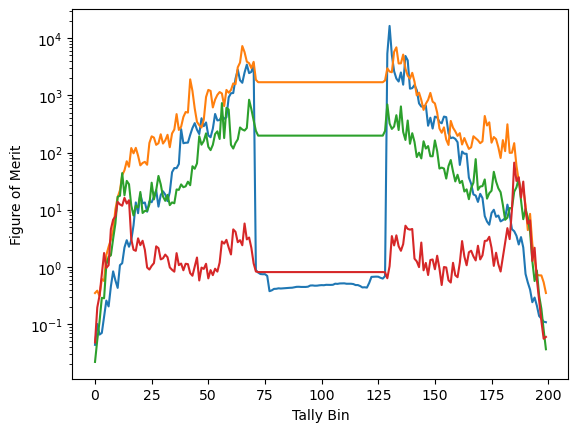

In [3]:
tally_result = simulation_symm.get_tally_results(quantities=['mean', 'rel_err'])

plt.semilogy(1 / (tally_result['flux']['rel_err']**2 * tally_result['runtime']))
plt.xlabel("Tally Bin")
_ = plt.ylabel("Figure of Merit")

We then directly setup a linear blanket simulation using 10 elements in all blanket layers.
The setup is very similar to the linear setup before, so we just use the already available functions of `mcbb` to generate the multi-group operator.

Then we run the FW-CADIS calculation to generate the importance map, which we interpolate (to have a smaller number of weight-window mesh elements) then convert to weight windows to show.

In [4]:
from mcbb.sn.base_sn import setup_linear_symm_mgop
from jax_sn.solvers.right_hand_side import IsotropicSourceSingleGroup
from mcbb.openmc_base_functions import _importance_map_to_weight_windows
import lineax as lx
from jax_sn.variance_reduction import fw_cadis_scalar_flux
degree = 3
tn_order = 3



mgop, source_basis, solution_domain = setup_linear_symm_mgop(hcpb_blanket, openmc_data[0], [10 for i in range(8)], degree, tn_order, multi_group_strategy = DefaultMultiGroupStrategy.default_multi_group_strategy())

rhs = IsotropicSourceSingleGroup.from_operator(mgop, source_basis)

solver = lx.BiCGStab(1e-10, 1e-10, max_steps = 200)
importance_map_solution = fw_cadis_scalar_flux(mgop, rhs, solver)



In [11]:
from jax_sn.tools.plotly import plot_domain


plot_domain(mgop.data.domain, material_names = list(hcpb_blanket.layer_names[::-1]) + list(hcpb_blanket.layer_names[1:]), show_element_boundaries = False)

After obtaining the importance map, we will interpolate it to define it on the mesh we will use later (simple linear spacing):


In [6]:
plasma_thickness = hcpb_blanket.layers[0].thickness
s_sample         =  jnp.linspace(plasma_thickness, hcpb_blanket.average_thickness, 20)
blanket_start    = sum(hcpb_blanket.average_thicknesses[1:])  # just use the right side of the blanket.
importance_map   = solution_domain.interpolate(blanket_start +s_sample[:, None], importance_map_solution[:, 0 , ...])    

We will now show the weight windows of this importance map by plotting it:

Text(0, 0.5, 'Weight Window Bounds')

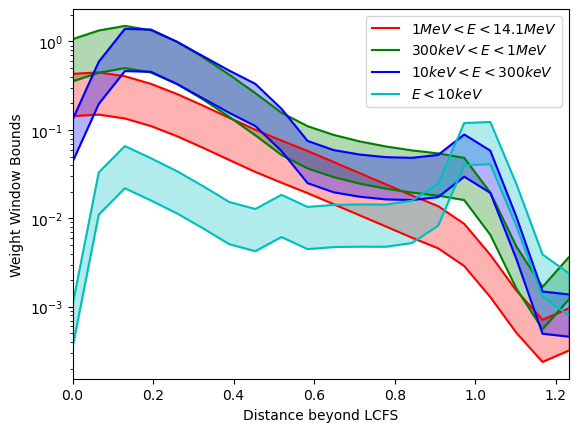

In [7]:
# Just for plotting; we build the weight windows directly from this importance map below.
ww_up, ww_down = _importance_map_to_weight_windows(importance_map, ww_lower_upper_ratio = 3)
colors = ['r','g','b','c']
d = s_sample - plasma_thickness # distance beyond the LCFS (start of the solid blanket)
energy_groups = ['$1 MeV < E < 14.1 MeV$', '$300 keV < E < 1 MeV$', '$10 keV < E < 300 keV$', '$E < 10 keV$']
for i in range(ww_up.shape[0]):
    plt.plot(d, ww_up[i, :], color=colors[i], label=energy_groups[i])
    plt.plot(d, ww_down[i, :], color=colors[i], linestyle='-')
    plt.fill_between(d,  ww_up[i, :], ww_down[i, :], color=colors[i], alpha=0.3)
plt.yscale('log')
plt.legend()
plt.xlim(0.00, hcpb_blanket.average_thickness - plasma_thickness)
plt.xlabel("Distance beyond LCFS")
plt.ylabel("Weight Window Bounds")

Now we create weight windows from it. We mirror it to the other side of the symmetric blanket, put into a rectilinear mesh and create a weight window object for OpenMC.
We use the convenience function `importance_map_to_weight_window` to handle the creation of the OpenMC weight window object.

In [8]:
from mcbb.openmc_base_functions import importance_map_to_weight_window
import openmc

blanket_start = sum(layer.thickness for layer in hcpb_blanket.layers[1:])  # everything except the plasma

front_importance = importance_map[:, ::-1]   # ascending in x, from x=0 up to x=blanket_start
back_importance  = importance_map              # ascending in x, from x=blanket_start+plasma_thickness to the back edge

front_cells = 0.5 * (front_importance[:, :-1] + front_importance[:, 1:])
back_cells  = 0.5 * (back_importance[:, :-1] + back_importance[:, 1:])
plasma_cell = jnp.full((importance_map.shape[0], 1), jnp.nan)  # no weight window inside the plasma itself

importance_map_elem = jnp.concatenate([front_cells, plasma_cell, back_cells], axis=1)

positions_front = blanket_start - d[::-1]                    # ascending, [0, blanket_start]
positions_back  = blanket_start + plasma_thickness + d       # ascending, [blanket_start + plasma_thickness, back edge]
mesh_edges      = onp.concatenate([positions_front, positions_back])  # meters, aligned with the geometry's own x=0 origin

mesh        = openmc.RectilinearMesh()
mesh.x_grid = mesh_edges * 1e2  # m -> cm
mesh.y_grid = [simulation_symm.geometry.bounding_box[0][1], simulation_symm.geometry.bounding_box[1][1]]
mesh.z_grid = [simulation_symm.geometry.bounding_box[0][2], simulation_symm.geometry.bounding_box[1][2]]

weight_windows = importance_map_to_weight_window(importance_map_elem, groups_list, mesh, ww_lower_upper_ratio=3, max_split=2000)

We generate the same simulation but with a weight window and run it. It will take slightly longer due to the weight windows splitting particles.

In [9]:
sim_2 = simulation_symm.with_weight_windows(weight_windows)

sim_2.run(statepoint_file = "statepoint.10_ww.h5")



Cached at statepoint file: statepoint.10_ww.h5


'statepoint.10_ww.h5'

We can now compare both figures of merit, showing $O(10^2)$ increase with weight windows in the edge!

/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/tallies.py:1859: RuntimeWarning:

invalid value encountered in divide



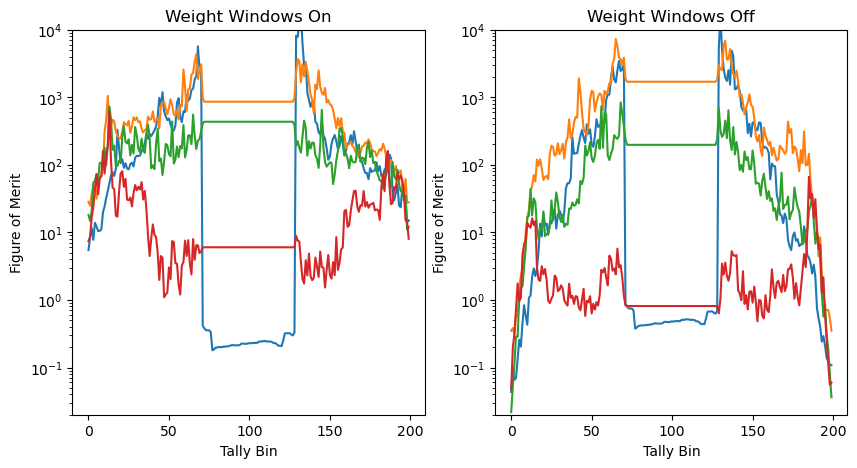

In [10]:
tally_result_ww = sim_2.get_tally_results(quantities=['mean', 'rel_err'])
fig, axs = plt.subplots(1,2, figsize = (10,5))

def _set_plot(ax, tally_result, title):
    ax.set_title(title)
    ax.semilogy(1 / (tally_result['flux']['rel_err']**2 * tally_result['runtime']))
    ax.set_ylim(2e-2, 1e4)
    ax.set_xlabel("Tally Bin")
    ax.set_ylabel("Figure of Merit")

_set_plot(axs[0], tally_result_ww, "Weight Windows On")
_set_plot(axs[1], tally_result, "Weight Windows Off")